# 10 — Đánh giá test | HSV12 + KNN

Cấu hình đã chọn trên dev: **HSV 12×12×12, chuẩn hóa L2; KNN k=1, uniform, Bray–Curtis**. Notebook này fit lại đúng cấu hình đó trên train và đánh giá toàn bộ test. Không tìm tham số, không gộp train/dev và không điều chỉnh theo kết quả test.

Đọc từng ảnh rồi giữ vector để tránh nạp toàn bộ ảnh gốc vào RAM. Không resize, augment hoặc sửa DATA. Trước khi chạy, restart kernel các notebook cũ. Khi đã có kết quả, phân tích lỗi để báo cáo; nếu phát triển phương án mới thì phải phân biệt với đánh giá cuối này.

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys
import json

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from IPython.display import display

PROJECT_ROOT = Path(r"C:\CS231")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.value_metrics import evaluate_classification

DATA_ROOT = PROJECT_ROOT / "DATA"

## 1. Khai báo cấu hình đã khóa

Các giá trị dưới đây đến từ kết quả dev, không chọn lại bằng test. Thứ tự lớp giống hàm đánh giá dùng chung. File đầu ra được lưu riêng trong `src/KNN/results/hsv12_test/`, không ghi đè các CSV dev.

In [2]:
HSV_BINS = 12
K = 1
WEIGHTS = "uniform"
METRIC = "braycurtis"
CLASS_NAMES = ["10000", "20000", "50000", "100000", "200000", "500000"]

output_dir = PROJECT_ROOT / "src" / "KNN" / "results" / "hsv12_test"
output_dir.mkdir(parents=True, exist_ok=True)

config = {
    "feature": "Histogram HSV 12x12x12",
    "feature_dim": HSV_BINS ** 3,
    "normalization": "L2",
    "k": K,
    "weights": WEIGHTS,
    "metric": METRIC,
    "algorithm": "brute",
    "fit_split": "train",
    "evaluation_split": "test",
    "selection_split": "dev",
    "selection_evidence": "src/KNN/results/hsv12_best_dev.csv",
    "class_order_vnd": [int(name) for name in CLASS_NAMES],
}
(output_dir / "hsv12_locked_config.json").write_text(
    json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Cấu hình:", config)

Cấu hình: {'feature': 'Histogram HSV 12x12x12', 'feature_dim': 1728, 'normalization': 'L2', 'k': 1, 'weights': 'uniform', 'metric': 'braycurtis', 'algorithm': 'brute', 'fit_split': 'train', 'evaluation_split': 'test', 'selection_split': 'dev', 'selection_evidence': 'src/KNN/results/hsv12_best_dev.csv', 'class_order_vnd': [10000, 20000, 50000, 100000, 200000, 500000]}


## 2. Đọc danh sách ảnh và nhãn

Chỉ lưu đường dẫn. Chưa đọc toàn bộ nội dung ảnh. Giữ cùng thứ tự đường dẫn khi tạo feature và lưu dự đoán để truy vết đúng ảnh.

In [3]:
def load_image_paths_from_folder(folder):
    image_paths = []
    labels = []
    for class_name in CLASS_NAMES:
        class_folder = Path(folder) / class_name
        for image_path in sorted(class_folder.glob("*.png")):
            image_paths.append(image_path)
            labels.append(int(class_name))
    return image_paths, np.asarray(labels, dtype=np.int64)


train_paths, y_train = load_image_paths_from_folder(DATA_ROOT / "train")
test_paths, y_test = load_image_paths_from_folder(DATA_ROOT / "test")

print("Số ảnh train:", len(train_paths), "| Nhãn:", len(y_train))
print("Số ảnh test:", len(test_paths), "| Nhãn:", len(y_test))

Số ảnh train: 12494 | Nhãn: 12494
Số ảnh test: 1553 | Nhãn: 1553


Dự kiến: **12.494 ảnh train** và **1.553 ảnh test**. Nếu số lượng không đúng, dừng để kiểm tra đường dẫn/DATA trước khi chạy tiếp. Không bỏ qua ảnh không đọc được vì sẽ làm thay đổi tập đánh giá.

## 3. Trích xuất HSV12

Giữ nguyên công thức notebook 08: BGR → RGB → HSV, histogram kết hợp ba kênh với miền H=[0,180), S/V=[0,256), chuẩn hóa L2. Mỗi ảnh có 1.728 phần tử. Không fit phép chuẩn hóa trên test; L2 được tính riêng trên histogram của từng ảnh.

In [4]:
HSV_BINS = 12 

def extract_hsv_histogram(image, bins=12):

    hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    hist = cv2.calcHist(
        [hsv_image], [0, 1, 2], None,
        [bins, bins, bins],
        [0, 180, 0, 256, 0, 256]
    )
    hist = cv2.normalize(hist, hist).flatten()
    return np.array(hist)

In [5]:
def extract_hsv_from_paths(image_paths):
    features = np.empty((len(image_paths), HSV_BINS ** 3), dtype=np.float32)
    for i, image_path in enumerate(image_paths):
        image_bgr = cv2.imread(str(image_path))
        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        features[i] = extract_hsv_histogram(image_rgb, bins=HSV_BINS)
        del image_bgr, image_rgb
    return features


X_train_hsv = extract_hsv_from_paths(train_paths)
X_test_hsv = extract_hsv_from_paths(test_paths)

print("Train:", X_train_hsv.shape, y_train.shape)
print("Test: ", X_test_hsv.shape, y_test.shape)

Train: (12494, 1728) (12494,)
Test:  (1553, 1728) (1553,)


## 4. Fit trên train và dự đoán test

Không có vòng lặp grid search. KNN giữ các vector train để tìm hàng xóm cho từng ảnh test; nhãn test chỉ được sử dụng sau dự đoán để chấm điểm.

In [6]:
knn = KNeighborsClassifier(
    n_neighbors=K,
    weights=WEIGHTS,
    metric=METRIC,
    algorithm="brute"
)
knn.fit(X_train_hsv, y_train)
y_test_pred = knn.predict(X_test_hsv)

## 5. Lưu dự đoán gắn với từng ảnh

`image_path` tính từ thư mục gốc repo, ví dụ `DATA/test/10000/10000_....png`. Chênh lệch là giá trị tuyệt đối giữa hai mệnh giá; ảnh đúng có chênh lệch 0.

In [7]:
predictions = pd.DataFrame({
    "image_path": [path.relative_to(PROJECT_ROOT).as_posix() for path in test_paths],
    "filename": [path.name for path in test_paths],
    "y_true": y_test,
    "y_pred": y_test_pred,
    "is_correct": y_test == y_test_pred,
    "gap_vnd": np.abs(y_test - y_test_pred),
})
predictions.to_csv(output_dir / "hsv12_predictions_test.csv", index=False)
print("Đã lưu dự đoán:", output_dir / "hsv12_predictions_test.csv")

Đã lưu dự đoán: C:\CS231\src\KNN\results\hsv12_test\hsv12_predictions_test.csv


## 6. Đánh giá bằng hàm dùng chung

Báo cáo toàn bộ test, không lọc ảnh khó. Macro-F1 là tiêu chí phân loại chính; MAE_VND mô tả chênh lệch mệnh giá trung bình trên tất cả ảnh, không phải tổn thất tài chính thực tế. Không chọn lại cấu hình bằng điểm test.

In [8]:
test_scores = evaluate_classification(y_test, y_test_pred)
summary_test = pd.DataFrame([{
    "feature": config["feature"],
    "feature_dim": HSV_BINS ** 3,
    "k": K,
    "weights": WEIGHTS,
    "metric": METRIC,
    "n_samples": test_scores["n_samples"],
    "accuracy": test_scores["accuracy"],
    "macro_f1": test_scores["macro_f1"],
    "mae_vnd": test_scores["mae_vnd"],
    "total_gap_vnd": test_scores["total_gap_vnd"],
}])
per_class_test = pd.DataFrame(test_scores["per_class"])
labels = test_scores["class_order_vnd"]
cm_test = np.asarray(test_scores["confusion_matrix"])

summary_test.to_csv(output_dir / "hsv12_summary_test.csv", index=False)
per_class_test.to_csv(output_dir / "hsv12_per_class_test.csv", index=False)
pd.DataFrame(cm_test, index=labels, columns=labels).to_csv(
    output_dir / "hsv12_confusion_matrix_test.csv"
)
(output_dir / "hsv12_metrics_test.json").write_text(
    json.dumps(test_scores, ensure_ascii=False, indent=2), encoding="utf-8"
)

display(summary_test)
display(per_class_test[["denomination_vnd", "support", "precision", "recall", "f1"]])
print("Số ảnh đúng:", int(np.trace(cm_test)), "/", len(y_test))

,feature,feature_dim,k,weights,metric,n_samples,accuracy,macro_f1,mae_vnd,total_gap_vnd
0,Histogram HSV 12x12x12,1728,1,uniform,braycurtis,1553,0.871861,0.874772,31461.687057,48860000


,denomination_vnd,support,precision,recall,f1
0,10000,281,0.865248,0.868327,0.866785
1,20000,224,0.855319,0.897321,0.875817
2,50000,223,0.938679,0.892377,0.914943
3,100000,247,0.912863,0.890688,0.901639
4,200000,317,0.834375,0.842271,0.838305
5,500000,261,0.847909,0.854406,0.851145


Số ảnh đúng: 1354 / 1553


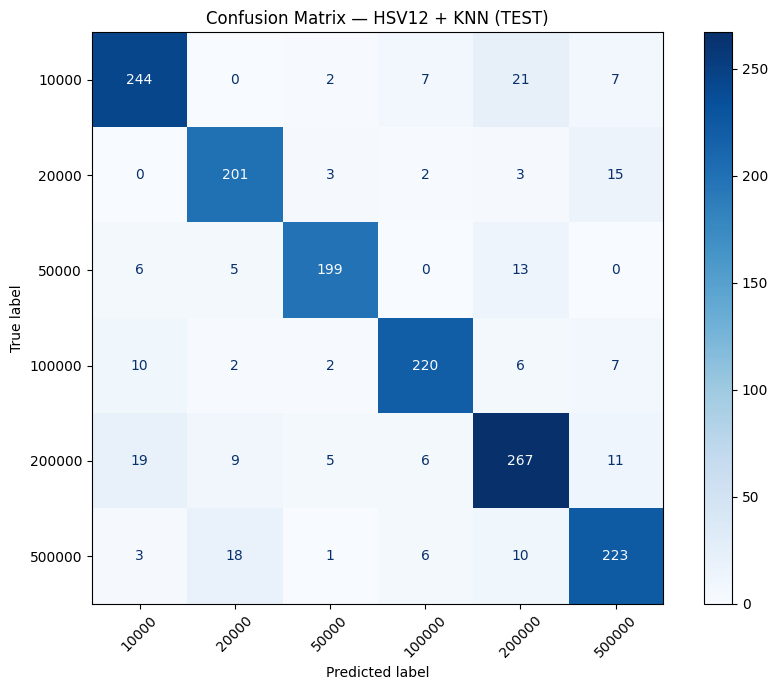

In [9]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=labels)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=45)
ax.set_title("Confusion Matrix — HSV12 + KNN (TEST)")
plt.tight_layout()
fig.savefig(output_dir / "hsv12_confusion_matrix_test.png", dpi=160)
plt.show()

## 7. Phân tích lỗi mệnh giá

Hai góc nhìn khác nhau: cặp nào sai nhiều nhất và cặp nào đóng góp tổng chênh lệch lớn nhất. Các cặp giữ riêng từng hướng, ví dụ 500000 → 10000 khác 10000 → 500000. Nếu không có lỗi, bảng và hình ảnh lỗi sẽ trống, không coi đó là lỗi chương trình.

In [10]:
error_pairs_test = pd.DataFrame(
    test_scores["error_pairs"],
    columns=["true_vnd", "predicted_vnd", "count", "gap_vnd", "total_gap_vnd"]
)
error_pairs_test = error_pairs_test.sort_values(
    "total_gap_vnd", ascending=False, kind="stable"
)
error_pairs_test.to_csv(output_dir / "hsv12_error_pairs_test.csv", index=False)

print("Cặp lỗi có tổng chênh lệch lớn nhất:")
display(error_pairs_test.head(10))
print("Cặp lỗi xuất hiện nhiều nhất:")
display(error_pairs_test.sort_values("count", ascending=False, kind="stable").head(10))

errors_test = predictions[predictions["is_correct"] == False].copy()
errors_test = errors_test.sort_values("gap_vnd", ascending=False, kind="stable")
errors_test.to_csv(output_dir / "hsv12_error_images_test.csv", index=False)
print("Số ảnh sai:", len(errors_test))

Cặp lỗi có tổng chênh lệch lớn nhất:


,true_vnd,predicted_vnd,count,gap_vnd,total_gap_vnd
22,500000,20000,18,480000,8640000
7,20000,500000,15,480000,7200000
2,10000,200000,21,190000,3990000
16,200000,10000,19,190000,3610000
3,10000,500000,7,490000,3430000
20,200000,500000,11,300000,3300000
25,500000,200000,10,300000,3000000
15,100000,500000,7,400000,2800000
24,500000,100000,6,400000,2400000
10,50000,200000,13,150000,1950000


Cặp lỗi xuất hiện nhiều nhất:


,true_vnd,predicted_vnd,count,gap_vnd,total_gap_vnd
2,10000,200000,21,190000,3990000
16,200000,10000,19,190000,3610000
22,500000,20000,18,480000,8640000
7,20000,500000,15,480000,7200000
10,50000,200000,13,150000,1950000
20,200000,500000,11,300000,3300000
25,500000,200000,10,300000,3000000
11,100000,10000,10,90000,900000
17,200000,20000,9,180000,1620000
3,10000,500000,7,490000,3430000


Số ảnh sai: 199


## 8. Xem tối đa sáu ảnh lỗi có chênh lệch lớn nhất

Đây là mẫu lỗi chọn theo chênh lệch, không phải mẫu đại diện ngẫu nhiên cho toàn test. Quan sát màu sắc, góc chụp, nền và vùng che khuất để mô tả từng trường hợp; không suy ra tỷ lệ điều kiện ảnh nếu chưa có nhãn điều kiện. Không dùng các ảnh này để sửa cấu hình rồi báo lại như một đánh giá test chưa xem.

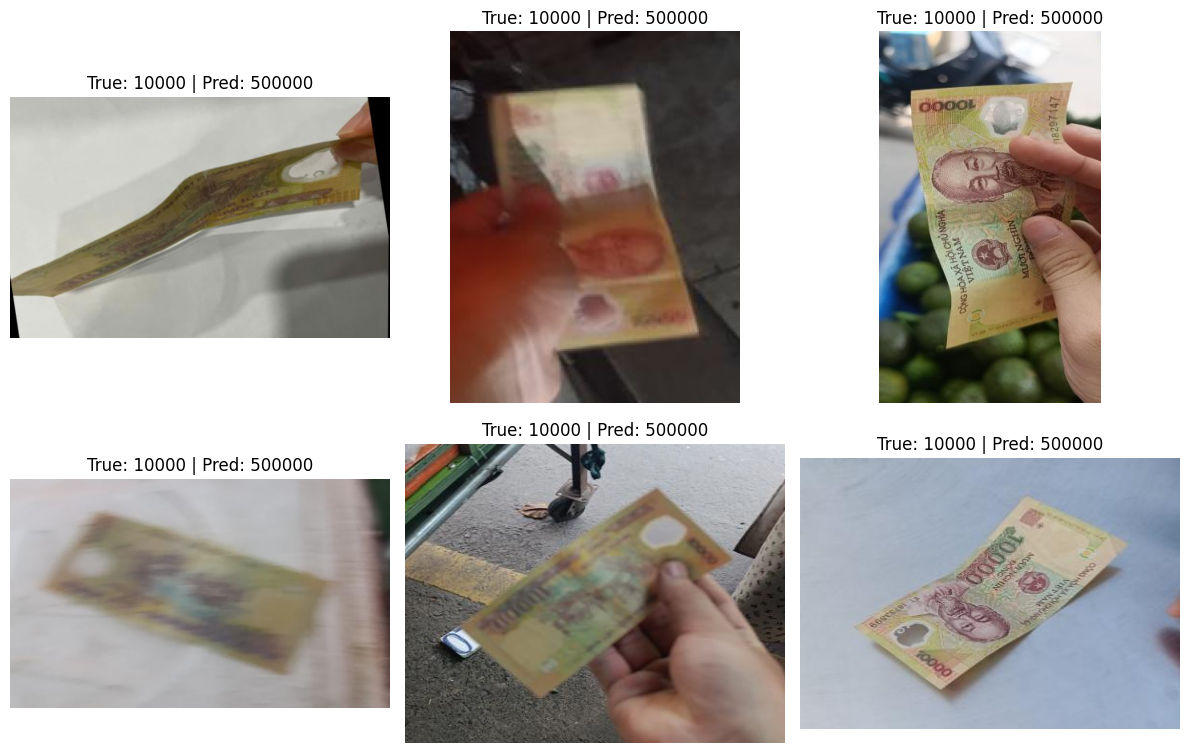

Thư mục kết quả: C:\CS231\src\KNN\results\hsv12_test


In [11]:
examples = errors_test.head(6)
if len(examples) > 0:
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, row) in zip(axes.flat, examples.iterrows()):
        image_bgr = cv2.imread(str(PROJECT_ROOT / row["image_path"]))
        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        ax.imshow(image_rgb)
        ax.set_title(f"True: {row['y_true']} | Pred: {row['y_pred']}")
    plt.tight_layout()
    fig.savefig(output_dir / "hsv12_largest_gap_errors_test.png", dpi=160)
    plt.show()
else:
    print("Không có ảnh dự đoán sai.")

print("Thư mục kết quả:", output_dir)

## 9. Nhận xét sau khi chạy

Điền nhận xét từ kết quả thật, không điền trước các con số:

- Accuracy, Macro-F1, MAE_VND trên test là bao nhiêu? Chênh lệch với dev HSV12 (Macro-F1 0,898057; Accuracy 0,893862; MAE 23.554,99 VND/ảnh) theo hướng nào? Khác biệt train/dev/test và việc đã chọn cấu hình trên dev là các yếu tố cần cân nhắc, chưa đủ để kết luận nguyên nhân duy nhất.
- Lớp nào có F1 thấp/cao nhất? Không nhầm F1 với Recall.
- Cặp lỗi nào nhiều nhất, cặp nào có tổng chênh lệch lớn nhất?
- Những ảnh lỗi đã xem cho thấy điều gì? Phân biệt quan sát từng ảnh với suy đoán chung.

Chạy xong dừng lại để kiểm tra tính nhất quán dự đoán/CSV/độ đo. Chưa chỉnh tiếp theo test và chưa gộp train+dev.